<a href="https://colab.research.google.com/github/mardocheeogecime-gif/Rede_Colabora-o_Acad-mica_ECI_UFMG/blob/main/HEQ_LAB_COMPLETO_CAPES_2013_2024_V2_SEPARACAO_CORRIGIDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HEQ — Laboratório completo corrigido: separação logística e suporte comum
Reutiliza cadastros congelados, não usa embeddings.
A regressão é restrita aos programas acadêmicos com suporte conjunto por área; não são estimados ORs da modalidade profissional quando não há eventos.

HEQ — LAB INDEPENDENTE COMPLETO | Estratificação institucional da pós-graduação brasileira (2013–2024)
Versão 1.0 | CPU | notebook autossuficiente, 3 células de execução extensas.

Pergunta: como a composição, estratificação avaliativa e distribuição institucional dos programas de pós-graduação stricto sensu no Brasil se organizam por dependência administrativa, modalidade e área de avaliação, e qual parcela produz teses/dissertações identificáveis na BTD CAPES?

Desenho: censo observacional de PPG–ano dos cadastros CAPES/Sucupira oficiais 2013–2024 (unidade PPG-ano), associado ao universo CAPES-BTD existente. A variável CD_CONCEITO_PROGRAMA é o conceito registrado no ano-base, NÃO a nota atribuída em avaliação naquele ano; seus saltos em 2017/2021 não são variações anuais de qualidade. A cobertura BTD não equivale à existência/ausência de produção científica. Não há inferência causal, nem comparação de embeddings.

Dados congelados exigidos: 58_LAB01_HEQ_2013_2024_V21_CONSOLIDACAO_OFICIAL/01_selected_official_resources.csv (12 CSV oficiais em V20, verificados por SHA-256); 59_LAB01_HEQ_2013_2024_V22_HOMOLOGACAO_ATRIBUTOS/02_ppg_year_official_extended_SAFE.parquet; 54_LAB01_HEQ_2013_2024_V17_INTEGRACAO_AUDITADA/02_full_ppg_year_attribute_audit.parquet. Os caminhos são os caminhos reais documentados nas etapas concluídas, nenhum placeholder de fonte.

Fluxo completo sem intervenção: 1) ler/validar cadastro censitário completo e montar painel; 2) tabelas, indicadores, regressões associativas com IC95% e robustez; 3) gráficos, tabelas de manuscrito, documento de interpretação, relatório final, manifestos. Os arquivos são isolados na pasta 68_HEQ_ESTRATIFICACAO_INSTITUCIONAL_CENSO_V1. O notebook imprime resultados e status da execução. Caso não exista uma coluna imprescindível, falha explicitamente com o esquema encontrado (não imputa valores inventados).

Aspectos centrais de validade: distingue conjunto oficial de PPGs do subconjunto com BTD; não interpreta A, 1, 2 como conceito 3–7; usa o cadastro completo, não apenas PPGs que aparecem na BTD, para analisar estratificação; preserva registros multivínculo sem expandir PPG-ano; avaliação por ciclo e padrões anuais descritos como estoques cadastrais. Toda regressão é associação condicional e seleção por covariáveis observadas, nunca efeito causal. Não usa embeddings M1/M4.


In [1]:
# CÉLULA 1/3 — CPU | CENSO CAPES OFICIAL, AUDITORIA E PAINEL INSTITUCIONAL
%pip -q install pandas numpy pyarrow scipy statsmodels matplotlib openpyxl
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd, numpy as np, re, unicodedata, json, hashlib, warnings
from IPython.display import display
try:
 from google.colab import drive
 drive.mount('/content/drive')
except ImportError:
 pass
ROOT=Path('/content/drive/MyDrive/CAPES_Epistemic_Change')
V21=ROOT/'58_LAB01_HEQ_2013_2024_V21_CONSOLIDACAO_OFICIAL'
V22=ROOT/'59_LAB01_HEQ_2013_2024_V22_HOMOLOGACAO_ATRIBUTOS'
V17=ROOT/'54_LAB01_HEQ_2013_2024_V17_INTEGRACAO_AUDITADA'
OUT=ROOT/'69_HEQ_ESTRATIFICACAO_INSTITUCIONAL_CENSO_V2_SEPARACAO_CORRIGIDA'
OUT.mkdir(parents=True,exist_ok=True)
SOURCES={
 'official_selection':V21/'01_selected_official_resources.csv',
 'official_BTD_crosswalk':V22/'02_ppg_year_official_extended_SAFE.parquet',
 'btd_audit':V17/'02_full_ppg_year_attribute_audit.parquet',
 'v21_handoff':V21/'03_v21_handoff.json',
 'v22_handoff':V22/'03_v22_handoff.json'
}
for k,p in SOURCES.items():
 if not p.is_file():raise FileNotFoundError(f'FONTE CONGELADA AUSENTE [{k}]: {p}')
def sha(path):
 h=hashlib.sha256()
 with open(path,'rb') as f:
  for block in iter(lambda:f.read(4*1024*1024),b''): h.update(block)
 return h.hexdigest()
def normal_name(s):
 return re.sub(r'[^A-Z0-9]+','_',unicodedata.normalize('NFKD',str(s).upper()).encode('ascii','ignore').decode()).strip('_')
def clean(s):
 v=s.astype('string').str.strip()
 return v.mask(v.isna() | v.str.upper().isin(['','NAN','NONE','NULL','<NA>','N/A']))
def readcsv(path):
 errors=[]
 for enc in ['utf-8-sig','latin1']:
  for sep in [';',',','\t']:
   try:
    df=pd.read_csv(path,sep=sep,encoding=enc,dtype='string',low_memory=False)
    if len(df.columns)>=10:return df
   except Exception as exc:errors.append(str(exc)[:120])
 raise ValueError(f'Não foi possível ler CSV multicoluna: {path}; exemplos erros: {errors[:3]}')
sel=pd.read_csv(SOURCES['official_selection'],dtype='string')
required_selection={'year_hint','local_path','sha256','resource_name'}
assert required_selection.issubset(sel.columns),sorted(required_selection-set(sel.columns))
sel['year_hint']=pd.to_numeric(sel.year_hint,errors='raise').astype(int)
assert len(sel)==12 and set(sel.year_hint)==set(range(2013,2025)) and sel.year_hint.is_unique
assert sel.local_path.nunique()==12
ALIASES={
 'ppg':['CD_PROGRAMA_IES'],'year':['AN_BASE'],
 'grade':['CD_CONCEITO_PROGRAMA'],
 'administration':['DS_DEPENDENCIA_ADMINISTRATIVA'],
 'legal_status':['CS_STATUS_JURIDICO'],
 'modality':['NM_MODALIDADE_PROGRAMA'],
 'degree':['NM_GRAU_PROGRAMA'],
 'area_code':['CD_AREA_AVALIACAO'],
 'area_name':['NM_AREA_AVALIACAO'],
 'ies_capes':['CD_ENTIDADE_CAPES'],
 'ies_emec':['CD_ENTIDADE_EMEC'],
 'ies_label':['SG_ENTIDADE_ENSINO'],
 'ies_name':['NM_ENTIDADE_ENSINO'],
 'municipality':['NM_MUNICIPIO_PROGRAMA_IES']
}
PARTS=[];SOURCE_AUDIT=[];CANDIDATE_FIELDS=set()
for r in sel.sort_values('year_hint').itertuples():
 fp=Path(str(r.local_path))
 if not fp.is_file():raise FileNotFoundError(f'CSV oficial anual ausente: {fp}')
 if sha(fp)!=str(r.sha256):raise ValueError(f'Hash SHA256 alterado do cadastro CAPES: {fp}')
 raw=readcsv(fp); cmap={normal_name(c):c for c in raw.columns};CANDIDATE_FIELDS.update(cmap)
 missing=[k for k,options in ALIASES.items() if not any(a in cmap for a in options)]
 if missing:raise ValueError(f'Esquema anual {r.year_hint} incompleto {missing}. Campos: {sorted(cmap)}')
 block=pd.DataFrame({k:clean(raw[next(cmap[a] for a in opts if a in cmap)]) for k,opts in ALIASES.items()})
 block.year=pd.to_numeric(block.year,errors='coerce').astype('Int64')
 if block[['ppg','year']].isna().any().any():raise ValueError(f'Chaves nulas no cadastro {r.year_hint}')
 if not block.year.eq(int(r.year_hint)).all():raise ValueError(f'AN_BASE inesperado no recurso {r.year_hint}: {block.year.value_counts().to_dict()}')
 block['year']=block.year.astype(int)
 block['source_resource']=str(r.resource_name)
 # Sem redefinir multivínculos por nome; identificar qualquer atributo conflitante para a mesma chave.
 dup=block.duplicated(['ppg','year']).sum()
 conflicting={k:int((block.groupby(['ppg','year'])[k].nunique(dropna=True)>1).sum()) for k in ['grade','administration','modality','area_code','ies_capes']}
 SOURCE_AUDIT.append({'year':int(r.year_hint),'file':str(fp),'sha256':str(r.sha256),'n_rows':len(block),
   'n_ppg_year':len(block.drop_duplicates(['ppg','year'])),'duplicate_key_rows':int(dup),
   **{'conflicts_'+k:v for k,v in conflicting.items()}})
 PARTS.append(block)
all_raw=pd.concat(PARTS,ignore_index=True)
assert all_raw.year.between(2013,2024).all()
raw_key=all_raw.groupby(['ppg','year'],dropna=False,sort=False)
AUD_ATTR=[k for k in ALIASES if k not in ['ppg','year']]
val_counts=raw_key[AUD_ATTR].nunique(dropna=True).reset_index()
val_counts=val_counts.rename(columns={k:'n_values_'+k for k in AUD_ATTR})
# Conflitos não são apagados; para a tabela de PPG-ano, somente valores não ambíguos.
first=all_raw.drop_duplicates(['ppg','year']).drop(columns='source_resource').copy()
census=first.merge(val_counts,on=['ppg','year'],validate='one_to_one')
for k in AUD_ATTR:
 census.loc[census['n_values_'+k].ne(1),k]=pd.NA
census['record_count']=raw_key.size().to_numpy() if False else 0
size=raw_key.size().rename('n_source_rows').reset_index()
census=census.drop(columns='record_count').merge(size,on=['ppg','year'],validate='one_to_one')
assert not census.duplicated(['ppg','year']).any()
assert len(census)>=48355, 'Censo oficial contém menos PPG-anos que a BTD auditada'
# Verificar cobertura com universo BTD e V22.
off_btd=pd.read_parquet(SOURCES['official_BTD_crosswalk'])
btd=pd.read_parquet(SOURCES['btd_audit'])
for df,label in [(off_btd,'V22'),(btd,'V17')]:
 if not {'ppg','year'}.issubset(df.columns):raise AssertionError(f'Esquema chaves {label}: {list(df.columns)}')
 df['ppg']=clean(df.ppg);df['year']=pd.to_numeric(df.year,errors='raise').astype(int)
 assert len(df)==48355 and not df.duplicated(['ppg','year']).any(),f'Integridade {label}'
keymatch=census[['ppg','year']].merge(btd[['ppg','year','n_docs','n_ies','safe_uf','safe_region']],on=['ppg','year'],how='left',indicator=True,validate='one_to_one')
assert int(keymatch._merge.eq('both').sum())==48355,'Pareamento com BTD não reproduziu a V21'
census=census.merge(btd[['ppg','year','n_docs','n_ies','safe_uf','safe_region']],on=['ppg','year'],how='left',validate='one_to_one',indicator=True)
census['has_btd_record']=census._merge.eq('both')
census=census.drop(columns='_merge')
census['n_docs']=pd.to_numeric(census.n_docs,errors='coerce').fillna(0).astype(int)
census['n_ies_btd']=pd.to_numeric(census.n_ies,errors='coerce').astype('Int64')
census=census.drop(columns='n_ies')
assert census.has_btd_record.sum()==48355 and census.loc[census.has_btd_record,'n_docs'].sum()==993086
# Conceito A,1,2: preservado no inventário mas excluído da comparação ordinal 3-7.
census['grade_numeric']=pd.to_numeric(census.grade.where(census.grade.isin(['3','4','5','6','7'])),errors='coerce').astype('float64')
census['valid_grade_3to7']=census.grade_numeric.notna()
census['high_grade_6_7']=np.where(census['valid_grade_3to7'].to_numpy(dtype=bool),census['grade_numeric'].ge(6).to_numpy(dtype=bool).astype(float),np.nan)
census['administration_norm']=census.administration.str.upper().str.strip()
census['modality_norm']=census.modality.str.upper().str.strip()
census['area_group']=census.area_code.fillna('AREA_NAO_INFORMADA')
census['is_public']=np.where(census.administration_norm.eq('PÚBLICA').fillna(False),1,np.where(census.administration_norm.eq('PRIVADA').fillna(False),0,np.nan))
census['is_professional']=np.where(census.modality_norm.eq('PROFISSIONAL').fillna(False),1,np.where(census.modality_norm.eq('ACADÊMICO').fillna(False),0,np.nan))
assert census.loc[census.has_btd_record,'administration'].notna().all()
# Aviso explícito: status legal/IES pode demandar documentação; nenhuma equivalência multipla presumida.
census['official_multi_relation']=census.n_source_rows.gt(1)
census['btd_multi_relation']=census.n_ies_btd.gt(1).fillna(False)
census.to_parquet(OUT/'01_OFFICIAL_PPG_YEAR_CENSUS.parquet',index=False)
pd.DataFrame(SOURCE_AUDIT).to_csv(OUT/'01_source_integrity_by_year.csv',index=False)
census.groupby('year').agg(n_official=('ppg','size'),n_with_BTD=('has_btd_record','sum'),n_docs_BTD=('n_docs','sum'),
 n_grade_3to7=('valid_grade_3to7','sum'),n_multi_official=('official_multi_relation','sum'),n_multi_BTD=('btd_multi_relation','sum')).reset_index().to_csv(OUT/'01_population_by_year.csv',index=False)
census.groupby(['year','grade'],dropna=False).size().rename('n_programs').reset_index().to_csv(OUT/'01_raw_grade_labels_by_year.csv',index=False)
census.groupby(['year','administration_norm','modality_norm'],dropna=False).size().rename('n').reset_index().to_csv(OUT/'01_admin_modality_values.csv',index=False)
print('CENSO OFICIAL:',len(census),'PPG-anos | BTD:',int(census.has_btd_record.sum()),'| docs BTD:',int(census.n_docs.sum()))
print('CONFLITOS (fontes oficiais):',pd.DataFrame(SOURCE_AUDIT)[[c for c in pd.DataFrame(SOURCE_AUDIT) if c.startswith('conflicts_')]].sum().to_dict())
print('COLUNAS DISPONÍVEIS:',sorted(CANDIDATE_FIELDS));display(pd.read_csv(OUT/'01_population_by_year.csv'))


Mounted at /content/drive
CENSO OFICIAL: 51901 PPG-anos | BTD: 48355 | docs BTD: 993086
CONFLITOS (fontes oficiais): {'conflicts_grade': 0, 'conflicts_administration': 0, 'conflicts_modality': 0, 'conflicts_area_code': 0, 'conflicts_ies_capes': 0}
COLUNAS DISPONÍVEIS: ['ANO_INICIO_PROGRAMA', 'AN_BASE', 'AN_INICIO_CURSO', 'AN_INICIO_PROGRAMA', 'CD_AREA_AVALIACAO', 'CD_CONCEITO_PROGRAMA', 'CD_ENTIDADE_CAPES', 'CD_ENTIDADE_EMEC', 'CD_PROGRAMA_IES', 'CS_STATUS_JURIDICO', 'DS_CLIENTELA_QUADRIENAL_2017', 'DS_DEPENDENCIA_ADMINISTRATIVA', 'DS_ORGANIZACAO_ACADEMICA', 'DS_SITUACAO_PROGRAMA', 'DT_SITUACAO_PROGRAMA', 'ID_ADD_FOTO_PROGRAMA', 'ID_ADD_FOTO_PROGRAMA_IES', 'IN_REDE', 'NM_AREA_AVALIACAO', 'NM_AREA_BASICA', 'NM_AREA_CONHECIMENTO', 'NM_ENTIDADE_ENSINO', 'NM_ESPECIALIDADE', 'NM_GRANDE_AREA_CONHECIMENTO', 'NM_GRAU_PROGRAMA', 'NM_MODALIDADE_PROGRAMA', 'NM_MUNICIPIO_PROGRAMA_IES', 'NM_PROGRAMA_IDIOMA', 'NM_PROGRAMA_IES', 'NM_REGIAO', 'NM_SUBAREA_CONHECIMENTO', 'SG_ENTIDADE_ENSINO', 'SG_ENTIDA

,year,n_official,n_with_BTD,n_docs_BTD,n_grade_3to7,n_multi_official,n_multi_BTD
0,2013,3568,3115,67431,3537,0,22
1,2014,3765,3331,70487,3748,0,25
2,2015,3946,3570,75666,3931,0,36
3,2016,4186,3764,80075,4177,0,45
4,2017,4347,3959,85137,4299,0,47
5,2018,4363,4157,90295,4298,0,54
6,2019,4570,4254,94349,4272,0,70
7,2020,4559,4243,79989,4223,0,69
8,2021,4709,4439,82600,4551,0,74
9,2022,4594,4479,83981,4476,0,86


In [2]:
# CÉLULA 2/3 — CPU | INDICADORES, SELETIVIDADE, MODELOS ASSOCIATIVOS E ROBUSTEZ
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
import traceback
# A análise principal usa o CENSO de PPG–ano, não apenas aqueles com registros BTD.
d=census.copy()
d['grade_band']=np.select([d.grade.isin(['1','2']),d.grade.eq('3').fillna(False),d.grade.eq('4').fillna(False),d.grade.eq('5').fillna(False),d.grade.isin(['6','7']),d.grade.eq('A').fillna(False)],
 ['1-2','3','4','5','6-7','A'],default='SEM_CATEGORIA')
# Proporções e IC95% de Wilson referem-se a uma superpopulação hipotética, não à incerteza de amostragem do censo.
def summarise(g):
 n=len(g);nvalid=int(g.valid_grade_3to7.sum());nhigh=int((g.high_grade_6_7==1).sum());nbtd=int(g.has_btd_record.sum())
 low,up=proportion_confint(nhigh,nvalid,method='wilson') if nvalid else (np.nan,np.nan)
 return pd.Series({'n_ppg_year':n,'n_grade_valid':nvalid,'n_high_6_7':nhigh,'share_high_6_7':nhigh/nvalid if nvalid else np.nan,
 'wilson_low':low,'wilson_high':up,'n_with_BTD':nbtd,'share_with_BTD':nbtd/n,'n_BTD_docs':int(g.n_docs.sum()),
 'mean_BTD_docs_among_observed':g.loc[g.has_btd_record,'n_docs'].mean()})
summary_tables={}
for name,keys in {'year':['year'],'year_administration':['year','administration_norm'],
 'year_modality':['year','modality_norm'],'year_area':['year','area_group'],
 'year_grade':['year','grade_band'],
 'year_administration_modality':['year','administration_norm','modality_norm']}.items():
 tbl=d.groupby(keys,dropna=False,observed=True).apply(summarise,include_groups=False).reset_index()
 # O ano-grupo de contagem do conjunto oficial é censitário; não aplicar testes de hipótese ao censo como se fosse amostra.
 tbl.to_csv(OUT/f'02_{name}_stratification.csv',index=False)
 summary_tables[name]=tbl
# Trajetórias cadastrais e entradas/saídas do cadastro (ausência pode refletir regime de registro)
keys_by_year={y:set(d.loc[d.year.eq(y),'ppg']) for y in range(2013,2025)}
entry=[]
for y in range(2013,2025):
 now=keys_by_year[y];prev=keys_by_year.get(y-1,set())
 entry.append({'year':y,'n_ppgs':len(now),'new_vs_previous':len(now-prev) if y>2013 else np.nan,
 'exited_vs_previous':len(prev-now) if y>2013 else np.nan,
 'retained_from_previous':len(now&prev) if y>2013 else np.nan})
pd.DataFrame(entry).to_csv(OUT/'02_program_registry_entry_exit.csv',index=False)
# Mudanças do conceito: fenômeno cadastral, não evento anual de avaliação.
z=d[['ppg','year','grade','administration_norm','modality_norm']].sort_values(['ppg','year'])
z['prev_year']=z.groupby('ppg').year.shift();z['prev_grade']=z.groupby('ppg').grade.shift()
trans=z.loc[z.year.sub(z.prev_year).eq(1)].copy()
trans['changed']=trans.grade.ne(trans.prev_grade).fillna(False)
trans.groupby('year').agg(n_pairs=('ppg','size'),n_grade_changes=('changed','sum'),change_share=('changed','mean')).reset_index().to_csv(OUT/'02_concept_registry_transition_by_year.csv',index=False)
# Concentração de teses/dissertações na subpopulação BTD, por PPG-ano (apenas volume de BTD, não toda produção CAPES)
concentration=[]
for yr,g in d.groupby('year'):
 vals=g.n_docs.to_numpy(dtype=float);tot=vals.sum();vals=np.sort(vals)
 share_top10=float(vals[-max(1,int(np.ceil(len(vals)*0.10))):].sum()/tot) if tot else np.nan
 x=np.sort(vals);n=len(x)
 gini=float((2*np.arange(1,n+1)-n-1).dot(x)/(n*x.sum())) if x.sum() else np.nan
 concentration.append({'year':int(yr),'n_official':n,'total_BTD_docs':int(tot),'gini_BTD_docs_including_zero':gini,'top10pct_ppg_share_BTD_docs':share_top10})
pd.DataFrame(concentration).to_csv(OUT/'02_BTD_concentration_by_year.csv',index=False)
# Modelo exploratório identificável: SOMENTE programas ACADÊMICOS.
# Uma modalidade sem qualquer caso 6–7 gera separação completa; não estimar um OR para ela.
# Para a associação público/privado, estimar dentro dos acadêmicos, ajustando pela área
# SOMENTE em áreas com suporte conjunto (duas dependências e dois desfechos observados).
model_records=[];coef_records=[];skipped=[];support_rows=[];structural_rows=[]
for yr in range(2013,2025):
    sub=d[(d.year==yr)&d.valid_grade_3to7&d.is_professional.notna()&d.is_public.notna()].copy()
    sub['high']=sub.high_grade_6_7.astype(int)
    for mode,label in [(0,'ACADEMICO'),(1,'PROFISSIONAL')]:
        t=sub.loc[sub.is_professional.eq(mode)]
        n=len(t);events=int(t.high.sum());
        structural_rows.append({'year':yr,'modality':label,'n_grade_3to7':n,'n_grade_6_7':events,
             'share_grade_6_7':events/n if n else np.nan,'no_events':bool(n>0 and events==0)})
structural=pd.DataFrame(structural_rows)
structural.to_csv(OUT/'02_grade_6_7_by_modality_annual.csv',index=False)
for yr in [2016,2020,2024]:
    sample=d[(d.year==yr)&d.valid_grade_3to7&d.is_professional.eq(0)&d.is_public.notna()&d.area_group.notna()].copy()
    sample['high']=sample.high_grade_6_7.astype(int)
    sample['public']=sample.is_public.astype(int)
    # Suporte estrito para não ajustar FE em células sem qualquer evento observado.
    good=[]
    for area,g in sample.groupby('area_group',dropna=False):
        tab=pd.crosstab(g.public,g.high).reindex(index=[0,1],columns=[0,1],fill_value=0)
        counts=tab.to_numpy()
        supported=bool((tab.sum(axis=1)>=5).all() and (tab.sum(axis=0)>0).all() and (counts>0).all())
        support_rows.append({'year':yr,'area_group':str(area),'n_academic':len(g),'n_public':int(tab.loc[1].sum()),
            'n_private':int(tab.loc[0].sum()),'n_public_high':int(tab.loc[1,1]),'n_private_high':int(tab.loc[0,1]),
            'supported_all_2x2_cells_positive':supported})
        if supported:good.append(area)
    estim=sample.loc[sample.area_group.isin(good)].copy()
    info={'year':yr,'scope':'ACADEMIC_ONLY','n_initial':len(sample),'n_model':len(estim),
          'n_areas_model':len(good),'n_omitted_unsupported_area':len(sample)-len(estim),
          'fraction_retained':len(estim)/len(sample) if len(sample) else 0.0}
    if len(estim)<250 or len(good)<3 or estim.public.nunique()<2 or estim.high.nunique()<2:
        skipped.append({**info,'reason':'Insufficient joint area/public/outcome overlap'});continue
    try:
        fitted=smf.glm('high ~ public + C(area_group)',data=estim,
                family=sm.families.Binomial()).fit(cov_type='HC1',maxiter=150,disp=0)
        b=float(fitted.params['public']);se=float(fitted.bse['public'])
        if (not fitted.converged or not np.isfinite([b,se]).all() or se<=0 or abs(b)>=10):
            raise RuntimeError('Non-identifiable or unstable estimate')
        info.update({'converged':True,'formula':'high ~ public + C(area_group)',
                     'deviance':float(fitted.deviance),'n_params':len(fitted.params)})
        model_records.append(info)
        coef_records.append({'year':yr,'term':'public_vs_private_ACADEMIC_ONLY','n':len(estim),
             'coefficient':b,'robust_SE':se,'OR_adjusted_associative':float(np.exp(b)),
             'CI95_low':float(np.exp(b-1.96*se)),'CI95_high':float(np.exp(b+1.96*se)),
             'p_value_descriptive_model':float(fitted.pvalues['public']),
             'n_areas':len(good),'support_retained':len(estim)/len(sample)})
        pd.DataFrame({'term':fitted.params.index,'beta':fitted.params.values,
            'robust_SE':fitted.bse.values,'p_value':fitted.pvalues.values}).to_csv(
            OUT/f'02_model_all_coefficients_{yr}.csv',index=False)
    except Exception as exc:
        skipped.append({**info,'reason':str(exc)})
pd.DataFrame(support_rows).to_csv(OUT/'02_academic_area_overlap_audit.csv',index=False)
pd.DataFrame(model_records).to_csv(OUT/'02_glm_fit_diagnostics.csv',index=False)
pd.DataFrame(coef_records,columns=['year','term','n','coefficient','robust_SE',
    'OR_adjusted_associative','CI95_low','CI95_high','p_value_descriptive_model',
    'n_areas','support_retained']).to_csv(OUT/'02_glm_adjusted_associations.csv',index=False)
pd.DataFrame(skipped,columns=['year','scope','n_initial','n_model','n_areas_model',
    'n_omitted_unsupported_area','fraction_retained','reason']).to_csv(OUT/'02_glm_model_exclusions.csv',index=False)
print('EVENTOS POR MODALIDADE — ZERO EVENTOS NÃO É UM OR FINITO:')
display(structural)
# Qualidade e abrangência estratificada dos registros BTD, incluindo os PPGs que constam do cadastro mas sem BTD observada
coverage=d.groupby(['year','grade_band','administration_norm','modality_norm'],dropna=False,observed=True).agg(
 n_official=('ppg','size'),n_btd=('has_btd_record','sum'),total_docs=('n_docs','sum')).reset_index()
coverage['fraction_with_btd']=coverage.n_btd/coverage.n_official
coverage.to_csv(OUT/'02_BTD_coverage_in_official_frame.csv',index=False)
print('ANÁLISE CONCLUÍDA | PPG-anos oficiais:',len(d),'| modelos ajustados convergentes:',len(model_records),
 '| exclusões/erros de modelo:',len(skipped))
display(summary_tables['year']);display(pd.read_csv(OUT/'02_glm_adjusted_associations.csv'))
if skipped:print('MODELOS NÃO ESTIMADOS (sem forçar resultados):',skipped)


EVENTOS POR MODALIDADE — ZERO EVENTOS NÃO É UM OR FINITO:


,year,modality,n_grade_3to7,n_grade_6_7,share_grade_6_7,no_events
0,2013,ACADEMICO,3055,415,0.135843,False
1,2013,PROFISSIONAL,482,0,0.000000,True
2,2014,ACADEMICO,3199,415,0.129728,False
3,2014,PROFISSIONAL,549,0,0.000000,True
4,2015,ACADEMICO,3318,415,0.125075,False
5,2015,PROFISSIONAL,613,0,0.000000,True
6,2016,ACADEMICO,3474,415,0.119459,False
7,2016,PROFISSIONAL,703,0,0.000000,True
8,2017,ACADEMICO,3560,498,0.139888,False
9,2017,PROFISSIONAL,739,0,0.000000,True


ANÁLISE CONCLUÍDA | PPG-anos oficiais: 51901 | modelos ajustados convergentes: 3 | exclusões/erros de modelo: 0


,year,n_ppg_year,n_grade_valid,n_high_6_7,share_high_6_7,wilson_low,wilson_high,n_with_BTD,share_with_BTD,n_BTD_docs,mean_BTD_docs_among_observed
0,2013,3568.0,3537.0,415.0,0.117331,0.107138,0.128354,3115.0,0.873038,67431.0,21.647191
1,2014,3765.0,3748.0,415.0,0.110726,0.101076,0.121173,3331.0,0.884728,70487.0,21.160913
2,2015,3946.0,3931.0,415.0,0.105571,0.096347,0.115565,3570.0,0.904714,75666.0,21.194958
3,2016,4186.0,4177.0,415.0,0.099354,0.090647,0.108797,3764.0,0.899188,80075.0,21.273911
4,2017,4347.0,4299.0,498.0,0.115841,0.106615,0.125752,3959.0,0.910743,85137.0,21.504673
5,2018,4363.0,4298.0,492.0,0.114472,0.105296,0.124337,4157.0,0.952785,90295.0,21.721193
6,2019,4570.0,4272.0,492.0,0.115169,0.105940,0.125089,4254.0,0.930853,94349.0,22.178890
7,2020,4559.0,4223.0,491.0,0.116268,0.106947,0.126287,4243.0,0.930687,79989.0,18.851992
8,2021,4709.0,4551.0,674.0,0.148099,0.138077,0.158716,4439.0,0.942663,82600.0,18.607795
9,2022,4594.0,4476.0,673.0,0.150357,0.140187,0.161128,4479.0,0.974967,83981.0,18.749944


,year,term,n,coefficient,robust_SE,OR_adjusted_associative,CI95_low,CI95_high,p_value_descriptive_model,n_areas,support_retained
0,2016,public_vs_private_ACADEMIC_ONLY,1623,0.158833,0.241624,1.172142,0.729971,1.882154,0.510952,17,0.467185
1,2020,public_vs_private_ACADEMIC_ONLY,1758,0.103267,0.202798,1.108788,0.745115,1.649960,0.610604,20,0.502573
2,2024,public_vs_private_ACADEMIC_ONLY,2387,-0.021777,0.154811,0.978458,0.722379,1.325318,0.888132,27,0.652542


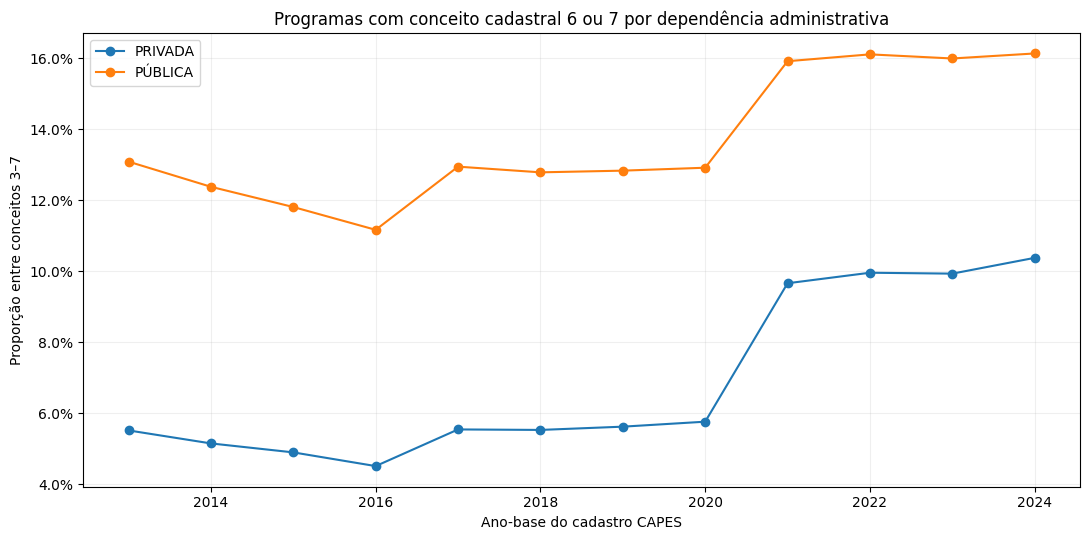

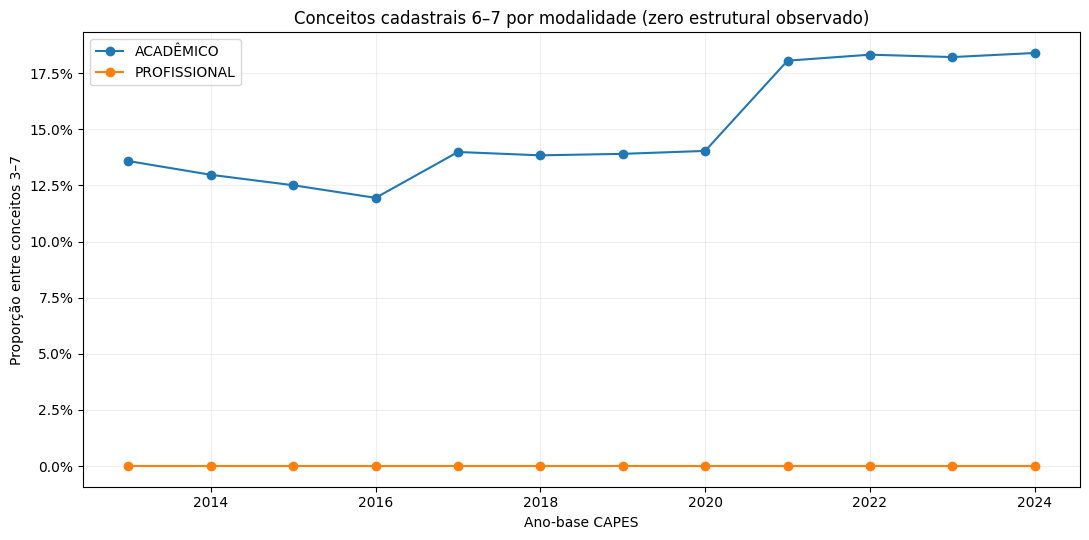

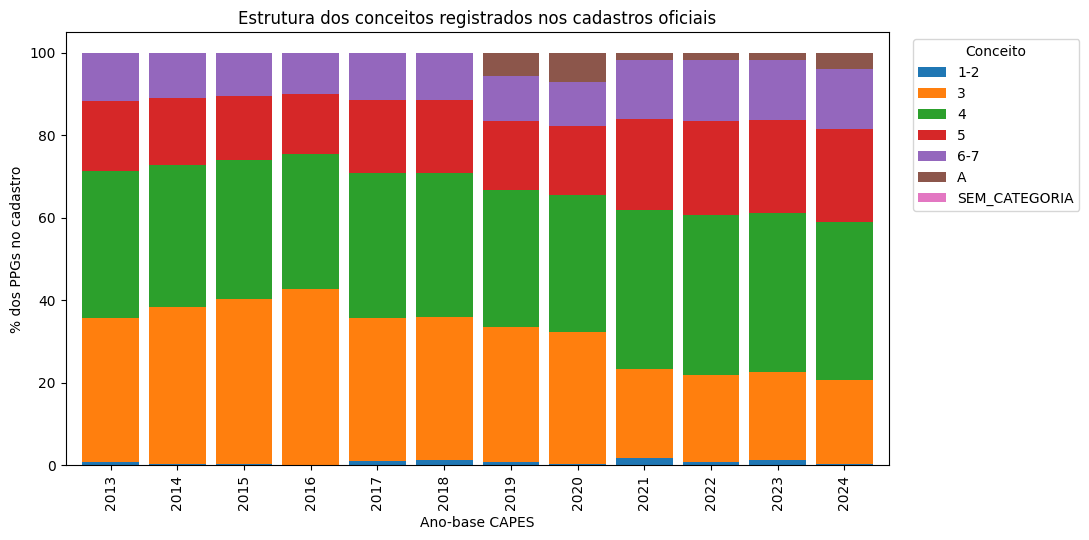

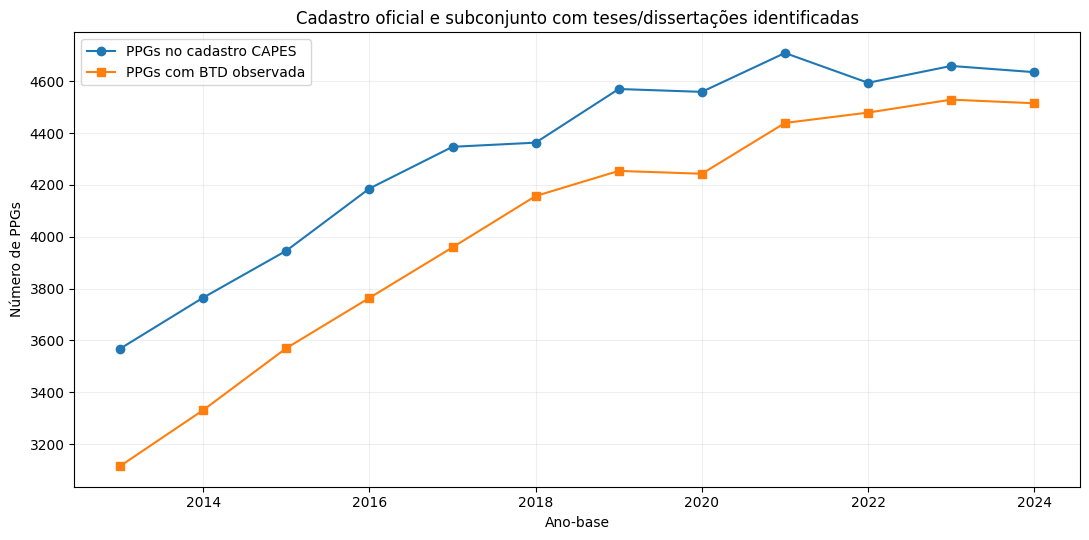

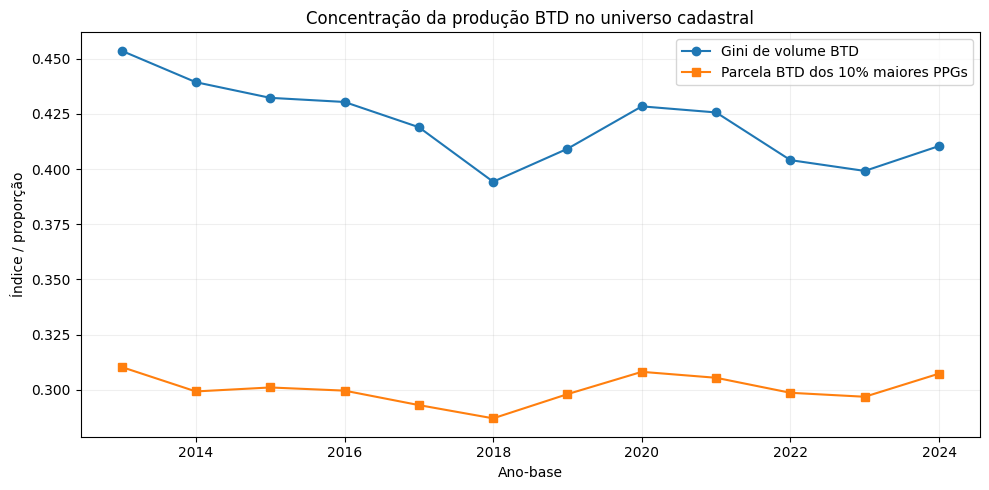

{
  "generated_utc": "2026-10-23T06:25:48.780695+00:00",
  "status": "COMPLETE_INSTITUTIONAL_REGISTRY_LAB_SEPARATION_CORRECTED",
  "source_scope": "FULL_OFFICIAL_CAPES_PPG_YEAR_2013_2024_PLUS_BTD_SUBSET",
  "years": [
    2013,
    2014,
    2015,
    2016,
    2017,
    2018,
    2019,
    2020,
    2021,
    2022,
    2023,
    2024
  ],
  "official_ppg_years": 51901,
  "btd_ppg_years": 48355,
  "btd_documents": 993086,
  "eligible_numeric_grade_3to7": 50465,
  "multi_ies_observations_from_BTD": 705,
  "official_duplicate_relation_ppg_year": 0,
  "regression_models_converged": 3,
  "regression_models_skipped": 0,
  "regression_scope": "ACADEMIC_ONLY_PUBLIC_VS_PRIVATE_WITH_AREA_OVERLAP",
  "professional_odds_ratio_estimated": false,
  "professional_6_7_count_all_years": 0,
  "figures": [
    "03_Fig1_high_grade_by_admin.png",
    "03_Fig2_high_grade_by_modality.png",
    "03_Fig3_grade_composition.png",
    "03_Fig4_official_vs_BTD.png",
    "03_Fig5_BTD_concentration.png"
  ],
  "tab

In [3]:
# CÉLULA 3/3 — CPU | TABELAS DE MANUSCRITO, FIGURAS, RELATÓRIO, CONTROLE FINAL
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
# Gráficos independentemente reproduzíveis. A série temporal representa CADASTRO ANUAL, não eventos anuais de avaliação.
plots=[]
fig,ax=plt.subplots(figsize=(11,5.5))
piv=summary_tables['year_administration'].pivot(index='year',columns='administration_norm',values='share_high_6_7')
for c in piv.columns:ax.plot(piv.index,piv[c],marker='o',label=str(c))
ax.set(title='Programas com conceito cadastral 6 ou 7 por dependência administrativa',xlabel='Ano-base do cadastro CAPES',ylabel='Proporção entre conceitos 3–7')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1));ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUT/'03_Fig1_high_grade_by_admin.png',dpi=210);plt.show();plt.close(fig)
plots.append('03_Fig1_high_grade_by_admin.png')
fig,ax=plt.subplots(figsize=(11,5.5))
piv=summary_tables['year_modality'].pivot(index='year',columns='modality_norm',values='share_high_6_7')
for c in piv.columns:ax.plot(piv.index,piv[c],marker='o',label=str(c))
ax.set(title='Conceitos cadastrais 6–7 por modalidade (zero estrutural observado)',xlabel='Ano-base CAPES',ylabel='Proporção entre conceitos 3–7')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1));ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUT/'03_Fig2_high_grade_by_modality.png',dpi=210);plt.show();plt.close(fig)
plots.append('03_Fig2_high_grade_by_modality.png')
fig,ax=plt.subplots(figsize=(11,5.5))
for k,grp in d.groupby('year'):
 pass
ct=d.groupby(['year','grade_band'],observed=True).size().unstack(fill_value=0)
ct=ct.reindex(columns=['1-2','3','4','5','6-7','A','SEM_CATEGORIA'],fill_value=0)
(ct.div(ct.sum(axis=1),axis=0)*100).plot(kind='bar',stacked=True,ax=ax,width=.85)
ax.set(title='Estrutura dos conceitos registrados nos cadastros oficiais',xlabel='Ano-base CAPES',ylabel='% dos PPGs no cadastro')
ax.legend(title='Conceito',bbox_to_anchor=(1.02,1),loc='upper left');fig.tight_layout()
fig.savefig(OUT/'03_Fig3_grade_composition.png',dpi=210);plt.show();plt.close(fig)
plots.append('03_Fig3_grade_composition.png')
fig,ax=plt.subplots(figsize=(11,5.5))
pop=pd.read_csv(OUT/'01_population_by_year.csv')
ax.plot(pop.year,pop.n_official,marker='o',label='PPGs no cadastro CAPES')
ax.plot(pop.year,pop.n_with_BTD,marker='s',label='PPGs com BTD observada')
ax.set(title='Cadastro oficial e subconjunto com teses/dissertações identificadas',xlabel='Ano-base',ylabel='Número de PPGs')
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUT/'03_Fig4_official_vs_BTD.png',dpi=210);plt.show();plt.close(fig)
plots.append('03_Fig4_official_vs_BTD.png')
fig,ax=plt.subplots(figsize=(10,5))
cc=pd.read_csv(OUT/'02_BTD_concentration_by_year.csv')
ax.plot(cc.year,cc.gini_BTD_docs_including_zero,marker='o',label='Gini de volume BTD')
ax.plot(cc.year,cc.top10pct_ppg_share_BTD_docs,marker='s',label='Parcela BTD dos 10% maiores PPGs')
ax.set(title='Concentração da produção BTD no universo cadastral',xlabel='Ano-base',ylabel='Índice / proporção')
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUT/'03_Fig5_BTD_concentration.png',dpi=210);plt.show();plt.close(fig)
plots.append('03_Fig5_BTD_concentration.png')
# Tabelas de síntese; arquivo editável Excel criado apenas como cópia de apresentação, fonte continua parquet/csv.
excel=OUT/'03_TABELAS_ARTIGO_HEQ.xlsx'
with pd.ExcelWriter(excel,engine='openpyxl') as writer:
 for sheet,file in [
  ('T1_censo_ano','01_population_by_year.csv'),
  ('T2_conceito_adm','02_year_administration_stratification.csv'),
  ('T3_conceito_modal','02_year_modality_stratification.csv'),
  ('T4_area','02_year_area_stratification.csv'),
  ('T5_regressao','02_glm_adjusted_associations.csv'),
  ('S1_registro','02_program_registry_entry_exit.csv'),
  ('S2_transicoes','02_concept_registry_transition_by_year.csv'),
  ('S3_concentracao','02_BTD_concentration_by_year.csv'),
  ('S4_selecao_BTD','02_BTD_coverage_in_official_frame.csv'),
  ('S5_qualidade_modelo','02_glm_fit_diagnostics.csv')]:
  pd.read_csv(OUT/file).to_excel(writer,sheet_name=sheet,index=False)
# Regras finais de integridade e checklist metodológico
assert len(d)==len(census) and not d.duplicated(['ppg','year']).any()
assert int(d.has_btd_record.sum())==48355
assert len(pd.read_csv(OUT/'01_population_by_year.csv'))==12
assert (pd.read_csv(OUT/'02_year_stratification.csv').n_ppg_year.sum()==len(d))
assert (d.loc[d.has_btd_record,'n_docs'].sum()==993086)
art="""# Estrutura e estratificação institucional da pós-graduação brasileira, 2013–2024

## Proposta de artigo — alinhamento preliminar a Higher Education Quarterly

**Título de trabalho:** Institutional Stratification and the Distribution of Postgraduate Programmes in Brazil, 2013–2024: A National Registry-Based Study.

**Problema:** descrever como dependência administrativa, modalidade e áreas de avaliação se articulam à composição e à estratificação por conceitos registrados nos cadastros de PPGs, distinguindo a população cadastral completa do subconjunto com teses/dissertações observadas nas bases BTD.

**Contribuição possível:** evidência nacional longitudinal **descritiva da estrutura cadastral**, acompanhada de estimativas condicionais transversais, sem confundir atualização de conceitos com variações anuais de qualidade. O estudo não utiliza embeddings nem mede diretamente diversificação de conhecimento.

## Definições operacionais

- Unidade: par PPG × ano-base entre 2013 e 2024.
- População principal: todos os PPGs constantes dos 12 arquivos oficiais da CAPES/Sucupira (não só PPGs com produção BTD).
- Dependência administrativa e modalidade: categorias oficiais registradas; seus rótulos são verificados empiricamente.
- Conceito: CD_CONCEITO_PROGRAMA *registrado no ano-base*. Categoria A e conceitos 1 e 2 separados; desfecho binário associativo utiliza 6–7 versus 3–5.
- Cobertura BTD: presença de pelo menos uma tese/dissertação na base congelada, não produção científica total.
- Indicadores de concentração: Gini e participação dos 10% maiores PPGs no total anual de documentos BTD, incluindo zeros dos PPGs sem BTD identificada.
- Regressões transversais ajustadas: 2016, 2020 e 2024, desfecho conceito 6–7, termos pública/privada e profissional/acadêmica, efeitos fixos de área, erros padrão robustos HC1; são **associações condicionais**, jamais efeitos causais. A seleção de áreas com variação no desfecho é relatada e restringe a população da estimativa.

## Limitações e alertas editoriais

1. Não converter saltos de conceito em 2017 ou 2021 em impactos das avaliações nesses anos. Atualização cadastral ≠ data de avaliação.
2. O conjunto CAPES-BTD é seletivo: PPG sem documento no arquivo não é necessariamente PPG sem produção acadêmica.
3. PPGs multi-institucionais não devem ser desdobrados em múltiplas observações sem uma estratégia explícita; a unidade PPG-ano mantém cardinalidade única.
4. `CD_ENTIDADE_EMEC` pode ter códigos especiais; não foi empregado como identificador institucional único na análise.
5. As categorias nominais de conceito e de status jurídico podem variar de interpretação institucional; os rótulos originais permanecem preservados.
6. O censo cobre registros administrativos e os IC95% de Wilson são descritivos de hipótese de superpopulação, não erro de amostragem de um censo completo.
7. A regressão com conceitos 6/7 não valida o mérito ou qualidade intrínseca de programas, nem corrige autoseleção institucional.
8. Esta abordagem oferece um caminho empiricamente consistente, mas adequação e originalidade para HEQ devem ser avaliadas antes de submissão. Requer diálogo teórico sobre estratificação institucional, diferenciação organizacional e desigualdade em sistemas de ensino superior.

## Organização recomendada do manuscrito

**Introdução:** hierarquias institucionais e diferenciação organizacional; lacuna de evidências longitudinais de registro. **Referencial:** estratificação horizontal/vertical; segmentação público/privado; profissionalização e diversidade disciplinar. **Métodos:** fontes oficiais, chaves, universo de registro, definição de conceitos e seus ciclos, separação completa da modalidade profissional, modelo associativo limitado aos PPGs acadêmicos e suporte comum por área. Resultados de regressão são condicionais ao subconjunto com suporte, não ao censo inteiro. **Resultados:** expansão de PPGs, composição por dependência/modalidade/área, distribuição de conceitos, desigualdade de participação na BTD, associações condicionais transversais. **Discussão:** mecanismos hipotéticos sem alegação causal; cobertura BTD e desafios de interpretação. **Limitações e conclusão.**

**Nota:** todas as tabelas e figuras são produzidas automaticamente. As estimativas numéricas definitivas devem ser copiadas exclusivamente dos arquivos desta execução, não de exemplos.
"""
(OUT/'03_MANUSCRIPT_PLAN_AND_METHODS.md').write_text(art,encoding='utf-8')
input_hash={k:sha(p) for k,p in SOURCES.items()}
files=[p for p in sorted(OUT.iterdir()) if p.is_file() and p.name!='03_output_manifest_sha256.csv']
pd.DataFrame([{'filename':p.name,'bytes':p.stat().st_size,'sha256':sha(p)} for p in files]).to_csv(OUT/'03_output_manifest_sha256.csv',index=False)
summary={
 'generated_utc':datetime.now(timezone.utc).isoformat(),
 'status':'COMPLETE_INSTITUTIONAL_REGISTRY_LAB_SEPARATION_CORRECTED',
 'source_scope':'FULL_OFFICIAL_CAPES_PPG_YEAR_2013_2024_PLUS_BTD_SUBSET',
 'years':list(range(2013,2025)),'official_ppg_years':int(len(d)),
 'btd_ppg_years':int(d.has_btd_record.sum()),'btd_documents':int(d.n_docs.sum()),
 'eligible_numeric_grade_3to7':int(d.valid_grade_3to7.sum()),
 'multi_ies_observations_from_BTD':int(d.btd_multi_relation.sum()),
 'official_duplicate_relation_ppg_year':int(d.official_multi_relation.sum()),
 'regression_models_converged':len(model_records),'regression_models_skipped':len(skipped),
 'regression_scope':'ACADEMIC_ONLY_PUBLIC_VS_PRIVATE_WITH_AREA_OVERLAP',
 'professional_odds_ratio_estimated':False,
 'professional_6_7_count_all_years':int(structural.loc[structural.modality.eq('PROFISSIONAL'),'n_grade_6_7'].sum()),
 'figures':plots,'tables_excel':excel.name,
 'semantic_embeddings_used':False,'causal_claims_allowed':False,
 'grade_temporal_claim':'REGISTERED_IN_AN_BASE_NOT_ANNUAL_EVALUATION_EVENT',
 'publication_ready':'REQUIRES_THEORY_AND_MANUSCRIPT_PEER_REVIEW',
 'source_sha256':input_hash
}
(OUT/'03_FINAL_HANDOFF.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
# incluir o handoff no manifesto final
files=[p for p in sorted(OUT.iterdir()) if p.is_file() and p.name!='03_output_manifest_sha256.csv']
pd.DataFrame([{'filename':p.name,'bytes':p.stat().st_size,'sha256':sha(p)} for p in files]).to_csv(OUT/'03_output_manifest_sha256.csv',index=False)
print(json.dumps(summary,ensure_ascii=False,indent=2));print('TODOS OS RESULTADOS:',OUT)


In [4]:

# ================================================================
# CÉLULA 4/4 — CPU
# HEQ | ENGLISH TABLE TITLES, FIGURE CAPTIONS AND NOTES
# Fonte: laboratório institucional CAPES 2013–2024 — V2
# Não recalcula análises; utiliza exclusivamente os artefatos gerados.
# ================================================================

from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown
import textwrap

ROOT = Path("/content/drive/MyDrive/CAPES_Epistemic_Change")
OUT = ROOT / "69_HEQ_ESTRATIFICACAO_INSTITUCIONAL_CENSO_V2_SEPARACAO_CORRIGIDA"

if not OUT.is_dir():
    raise FileNotFoundError(f"Results directory not found: {OUT}")

# ------------------------------------------------
# MAIN MANUSCRIPT TABLES
# ------------------------------------------------

tables = [
    {
        "label": "Table 1",
        "title": "Structure and coverage of Brazilian postgraduate programmes, 2013–2024",
        "file": "01_population_by_year.csv",
        "note": (
            "The unit of observation is the postgraduate programme-year. "
            "The official CAPES/Sucupira register defines the programme population. "
            "BTD coverage indicates programmes with at least one thesis or "
            "dissertation identified in the frozen CAPES BTD dataset, "
            "not necessarily programmes with any academic output."
        )
    },
    {
        "label": "Table 2",
        "title": (
            "Distribution of registered CAPES programme grades "
            "by administrative sector, 2013–2024"
        ),
        "file": "02_year_administration_stratification.csv",
        "note": (
            "Public and private sectors are defined using the official "
            "administrative-dependency field. The proportion of grades 6–7 "
            "is calculated among programmes with registered grades 3–7. "
            "Grades describe the value recorded for the reference year "
            "and must not be interpreted as an evaluation event in that year."
        )
    },
    {
        "label": "Table 3",
        "title": (
            "Distribution of registered CAPES programme grades "
            "by academic and professional modality, 2013–2024"
        ),
        "file": "02_year_modality_stratification.csv",
        "note": (
            "The academic and professional categories follow the official "
            "programme registry. No professional programme with a registered "
            "grade of 6 or 7 was observed in the analysed records. "
            "This zero-event pattern should not be interpreted as an "
            "estimated zero odds ratio or an intrinsic quality difference."
        )
    },
    {
        "label": "Table 4",
        "title": (
            "Disciplinary distribution and grade composition "
            "of Brazilian postgraduate programmes, 2013–2024"
        ),
        "file": "02_year_area_stratification.csv",
        "note": (
            "Disciplinary groups follow the official CAPES evaluation-area "
            "classification. Counts refer to registered programmes, "
            "not publications, researchers or higher education institutions. "
            "Grade comparisons are descriptive and may reflect differences "
            "in programme composition."
        )
    },
    {
        "label": "Table 5",
        "title": (
            "Adjusted associations between administrative sector and "
            "registered grades 6–7 among academic postgraduate programmes: "
            "Brazil, 2016, 2020 and 2024"
        ),
        "file": "02_glm_adjusted_associations.csv",
        "note": (
            "Odds ratios compare public with private academic programmes, "
            "conditional on CAPES evaluation area and restricted to areas "
            "with the required variation and common support. "
            "The binary outcome contrasts grades 6–7 with grades 3–5. "
            "Confidence intervals are based on HC1 robust standard errors. "
            "Sample size, number of included areas and support retained "
            "differ across years. Estimates are associational, not causal. "
            "Professional programmes were excluded from these regressions "
            "because no grade 6–7 events were observed in that modality."
        )
    }
]

# ------------------------------------------------
# MAIN MANUSCRIPT FIGURES
# ------------------------------------------------

figures = [
    {
        "label": "Figure 1",
        "title": (
            "Share of postgraduate programmes with registered CAPES "
            "grades 6–7 by administrative sector, Brazil, 2013–2024"
        ),
        "file": "03_Fig1_high_grade_by_admin.png",
        "note": (
            "Annual proportions are calculated among programmes with "
            "registered grades 3–7, separately for public and private "
            "administrative sectors. Changes across reference years may "
            "reflect periodic evaluation updates and shifts in the "
            "composition of the programme population."
        )
    },
    {
        "label": "Figure 2",
        "title": (
            "Share of postgraduate programmes with registered CAPES "
            "grades 6–7 by academic and professional modality, "
            "Brazil, 2013–2024"
        ),
        "file": "03_Fig2_high_grade_by_modality.png",
        "note": (
            "Annual proportions are calculated among programmes with "
            "registered grades 3–7. The professional modality has no "
            "observed grades 6–7 in these records. "
            "The figure describes registered grade distributions "
            "and does not establish equivalent evaluation opportunities "
            "or intrinsic performance differences across modalities."
        )
    },
    {
        "label": "Figure 3",
        "title": (
            "Composition of registered CAPES programme grades "
            "in Brazilian postgraduate education, 2013–2024"
        ),
        "file": "03_Fig3_grade_composition.png",
        "note": (
            "Stacked percentages use all postgraduate programmes in each "
            "annual official register as the denominator. "
            "Grades 1–2 and 6–7 are grouped for presentation, "
            "while grade A and uncategorised entries remain distinct. "
            "Year-to-year changes should not be interpreted as independent "
            "annual changes in educational quality."
        )
    },
    {
        "label": "Figure 4",
        "title": (
            "Postgraduate programmes in the official CAPES register "
            "and programmes with identified theses or dissertations, "
            "Brazil, 2013–2024"
        ),
        "file": "03_Fig4_official_vs_BTD.png",
        "note": (
            "The official series includes all matched programme-year "
            "records in the annual CAPES/Sucupira registers. "
            "The BTD series includes programmes with at least one "
            "thesis or dissertation identified in the frozen dataset. "
            "Differences between series should not automatically be "
            "interpreted as programmes without postgraduate output."
        )
    },
    {
        "label": "Figure 5",
        "title": (
            "Concentration of identified thesis and dissertation output "
            "across Brazilian postgraduate programmes, 2013–2024"
        ),
        "file": "03_Fig5_BTD_concentration.png",
        "note": (
            "The Gini coefficient summarises the distribution of "
            "identified BTD document counts across all programmes "
            "in the official annual register, including zero observed "
            "counts. The top-decile share represents the fraction "
            "of identified BTD documents attributed to the 10% of "
            "programmes with the largest annual BTD counts. "
            "Both measures refer to the observed dataset rather "
            "than all scientific publications or verified total output."
        )
    }
]

# ------------------------------------------------
# SUPPLEMENTARY TABLES
# ------------------------------------------------

supplementary = [
    {
        "label": "Supplementary Table S1",
        "title": (
            "Observed entries and exits in the annual postgraduate "
            "programme registry, 2013–2024"
        ),
        "file": "02_program_registry_entry_exit.csv",
        "note": (
            "Entry and exit refer to changes in the observed annual "
            "registry. They do not independently establish programme "
            "creation, termination or administrative closure."
        )
    },
    {
        "label": "Supplementary Table S2",
        "title": (
            "Year-to-year changes in registered CAPES programme grades "
            "among programmes observed in consecutive years"
        ),
        "file": "02_concept_registry_transition_by_year.csv",
        "note": (
            "Changes in registered grade values are descriptive "
            "of successive annual records and are not necessarily "
            "evaluation events occurring in the corresponding years."
        )
    },
    {
        "label": "Supplementary Table S3",
        "title": (
            "Annual Gini coefficients and top-decile shares "
            "of identified thesis and dissertation output, 2013–2024"
        ),
        "file": "02_BTD_concentration_by_year.csv",
        "note": (
            "The denominator includes programmes in the official "
            "registry with zero identified BTD documents. "
            "Concentration estimates refer only to the frozen "
            "thesis and dissertation dataset."
        )
    },
    {
        "label": "Supplementary Table S4",
        "title": (
            "Coverage of identified thesis and dissertation records "
            "within the official postgraduate programme population"
        ),
        "file": "02_BTD_coverage_in_official_frame.csv",
        "note": (
            "Coverage reflects successful observation of at least "
            "one BTD document and should not be interpreted as "
            "a direct measure of programme productivity."
        )
    },
    {
        "label": "Supplementary Table S5",
        "title": (
            "Estimation diagnostics and common-support restrictions "
            "for the area-adjusted logistic regression models"
        ),
        "file": "02_glm_fit_diagnostics.csv",
        "note": (
            "Diagnostics refer to the three academic-only "
            "cross-sectional association models. "
            "The professional-modality coefficient is not estimated "
            "because the relevant outcome category has zero "
            "observed events."
        )
    }
]

# ------------------------------------------------
# VALIDATE FILES AND PRINT LABELS
# ------------------------------------------------

catalogue = []
for section, records in [
    ("MAIN TABLES", tables),
    ("MAIN FIGURES", figures),
    ("SUPPLEMENTARY TABLES", supplementary)
]:
    print("\n" + "=" * 88)
    print(section)
    print("=" * 88)

    for item in records:
        exists = (OUT / item["file"]).is_file()
        status = "FOUND" if exists else "FILE NOT FOUND"

        print(f"\n{item['label']}. {item['title']}")
        print("\nNote. " + textwrap.fill(
            item["note"], width=94, subsequent_indent="      "
        ))
        print(f"Source file: {item['file']} [{status}]")

        catalogue.append({
            "section": section,
            "label": item["label"],
            "title": item["title"],
            "note": item["note"],
            "source_file": item["file"],
            "file_exists": exists
        })

# ------------------------------------------------
# SAVE ENGLISH CAPTIONS FOR MANUSCRIPT AUTHORING
# ------------------------------------------------

df_catalogue = pd.DataFrame(catalogue)

csv_path = OUT / "04_HEQ_ENGLISH_TABLE_FIGURE_CAPTIONS.csv"
md_path = OUT / "04_HEQ_ENGLISH_TABLE_FIGURE_CAPTIONS.md"

df_catalogue.to_csv(csv_path, index=False, encoding="utf-8-sig")

lines = [
    "# Higher Education Quarterly — Tables and Figures",
    "",
    "## English titles, captions and methodological notes",
    ""
]

for section, records in [
    ("Main Tables", tables),
    ("Main Figures", figures),
    ("Supplementary Tables", supplementary)
]:
    lines.extend([f"## {section}", ""])

    for item in records:
        lines.extend([
            f"### {item['label']}. {item['title']}",
            "",
            f"**Note.** {item['note']}",
            "",
            f"*Source file:* `{item['file']}`",
            ""
        ])

md_path.write_text("\n".join(lines), encoding="utf-8")

print("\n" + "=" * 88)
print("ENGLISH CAPTION CATALOGUE CREATED")
print("=" * 88)
print(f"Main tables: {len(tables)}")
print(f"Main figures: {len(figures)}")
print(f"Supplementary tables: {len(supplementary)}")
print(f"Files verified: {df_catalogue.file_exists.sum()}/{len(df_catalogue)}")
print(f"\nCSV: {csv_path}")
print(f"Markdown: {md_path}")

if not df_catalogue.file_exists.all():
    print("\nWARNING: Some expected files were not found.")
    display(df_catalogue.loc[~df_catalogue.file_exists,
                              ["label", "source_file"]])

display(df_catalogue[["label", "title", "file_exists"]])



MAIN TABLES

Table 1. Structure and coverage of Brazilian postgraduate programmes, 2013–2024

Note. The unit of observation is the postgraduate programme-year. The official CAPES/Sucupira
      register defines the programme population. BTD coverage indicates programmes with at
      least one thesis or dissertation identified in the frozen CAPES BTD dataset, not
      necessarily programmes with any academic output.
Source file: 01_population_by_year.csv [FOUND]

Table 2. Distribution of registered CAPES programme grades by administrative sector, 2013–2024

Note. Public and private sectors are defined using the official administrative-dependency field. The
      proportion of grades 6–7 is calculated among programmes with registered grades 3–7.
      Grades describe the value recorded for the reference year and must not be interpreted as
      an evaluation event in that year.
Source file: 02_year_administration_stratification.csv [FOUND]

Table 3. Distribution of registered CAPES pr

,label,title,file_exists
0,Table 1,Structure and coverage of Brazilian postgradua...,True
1,Table 2,Distribution of registered CAPES programme gra...,True
2,Table 3,Distribution of registered CAPES programme gra...,True
3,Table 4,Disciplinary distribution and grade compositio...,True
4,Table 5,Adjusted associations between administrative s...,True
5,Figure 1,Share of postgraduate programmes with register...,True
6,Figure 2,Share of postgraduate programmes with register...,True
7,Figure 3,Composition of registered CAPES programme grad...,True
8,Figure 4,Postgraduate programmes in the official CAPES ...,True
9,Figure 5,Concentration of identified thesis and dissert...,True


### Table 1. Official postgraduate programme registry and identified theses/dissertations, 2013–2024

,Year,Registered programmes (n),Programmes with identified T/D (n),Identified T/D (n),Programmes with grades 3–7 (n),n_multi_official,n_multi_BTD
0,2013,3568,3115,67431,3537,0,22
1,2014,3765,3331,70487,3748,0,25
2,2015,3946,3570,75666,3931,0,36
3,2016,4186,3764,80075,4177,0,45
4,2017,4347,3959,85137,4299,0,47
5,2018,4363,4157,90295,4298,0,54
6,2019,4570,4254,94349,4272,0,70
7,2020,4559,4243,79989,4223,0,69
8,2021,4709,4439,82600,4551,0,74
9,2022,4594,4479,83981,4476,0,86


English table saved: /content/drive/MyDrive/CAPES_Epistemic_Change/69_HEQ_ESTRATIFICACAO_INSTITUCIONAL_CENSO_V2_SEPARACAO_CORRIGIDA/04_ENGLISH_ARTICLE_OUTPUTS/Table_1_EN.csv | 12 rows


### Table 2. Registered CAPES grades by administrative sector, 2013–2024

,Year,Administrative sector,Programmes (n),Programmes with grades 3–7 (n),Programmes with grades 6–7 (n),Share with grades 6–7,Wilson 95% lower limit,Wilson 95% upper limit,Programmes with identified T/D (n),Share with identified T/D,Identified T/D (n),Mean T/D among observed programmes
0,2013,Private,653.0,634.0,35.0,0.055205,0.039959,0.075809,570.0,0.872894,12073.0,21.180702
1,2013,Public,2915.0,2903.0,380.0,0.130899,0.119116,0.143658,2545.0,0.873070,55358.0,21.751670
2,2014,Private,690.0,679.0,35.0,0.051546,0.037294,0.070844,600.0,0.869565,12629.0,21.048333
3,2014,Public,3075.0,3069.0,380.0,0.123819,0.112634,0.135944,2731.0,0.888130,57858.0,21.185646
4,2015,Private,723.0,714.0,35.0,0.049020,0.035455,0.067411,655.0,0.905947,14343.0,21.897710
5,2015,Public,3223.0,3217.0,380.0,0.118122,0.107422,0.129734,2915.0,0.904437,61323.0,21.037050
6,2016,Private,780.0,775.0,35.0,0.045161,0.032649,0.062160,692.0,0.887179,15055.0,21.755780
7,2016,Public,3406.0,3402.0,380.0,0.111699,0.101549,0.122725,3072.0,0.901938,65020.0,21.165365
8,2017,Private,802.0,793.0,44.0,0.055485,0.041590,0.073667,732.0,0.912718,16232.0,22.174863
9,2017,Public,3545.0,3506.0,454.0,0.129492,0.118783,0.141013,3227.0,0.910296,68905.0,21.352650


...

### Supplementary Table S5. Model diagnostics for academic-programme area-adjusted regressions

,Year,scope,n_initial,n_model,n_areas_model,n_omitted_unsupported_area,fraction_retained,converged,formula,deviance,n_params
0,2016,ACADEMIC_ONLY,3474,1623,17,1851,0.467185,True,high ~ public + C(area_group),1006.751955,18
1,2020,ACADEMIC_ONLY,3498,1758,20,1740,0.502573,True,high ~ public + C(area_group),1195.199670,21
2,2024,ACADEMIC_ONLY,3658,2387,27,1271,0.652542,True,high ~ public + C(area_group),2055.077620,28


English table saved: /content/drive/MyDrive/CAPES_Epistemic_Change/69_HEQ_ESTRATIFICACAO_INSTITUCIONAL_CENSO_V2_SEPARACAO_CORRIGIDA/04_ENGLISH_ARTICLE_OUTPUTS/Supplementary_Table_S5_EN.csv | 3 rows


### Figure 1. Share of programmes with registered CAPES grades 6–7 by administrative sector, Brazil, 2013–2024

**Note.** The denominator includes programmes with grades 3–7 in each administrative sector and year; recorded grades do not identify annual evaluation events.

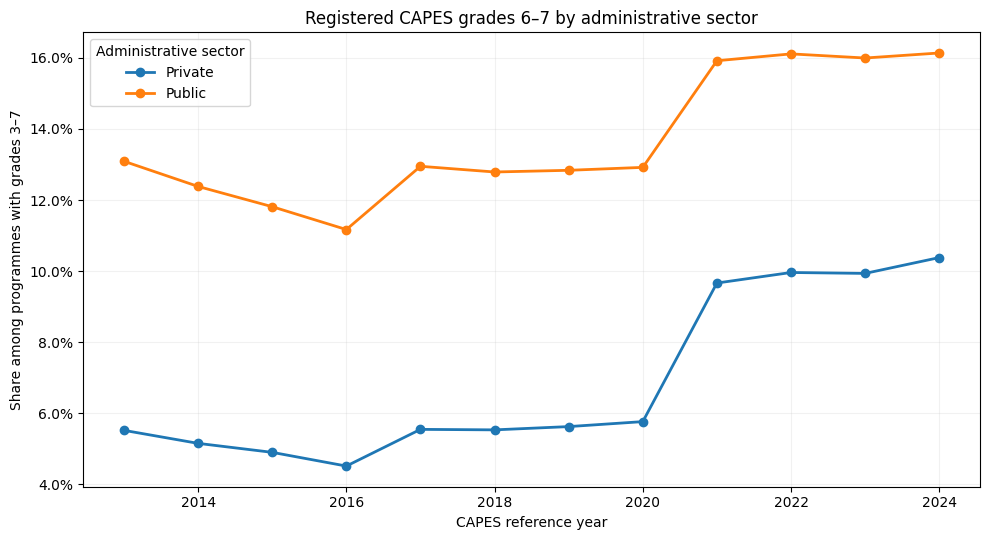

### Figure 2. Share of programmes with registered CAPES grades 6–7 by academic or professional modality, Brazil, 2013–2024

**Note.** No grade 6–7 was observed for professional programmes in the analysed registry; this is a descriptive zero, not an estimated odds ratio or proof of equivalent evaluation rules.

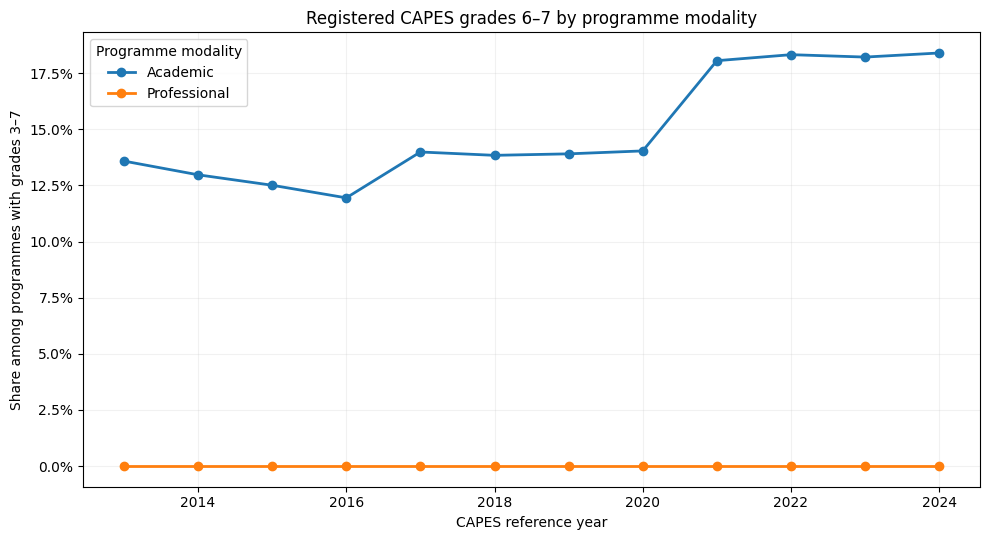

### Figure 3. Distribution of registered CAPES programme grades in Brazil, 2013–2024

**Note.** The denominator includes all programmes in the official register for each year. Grade A and uncategorised records are displayed separately.

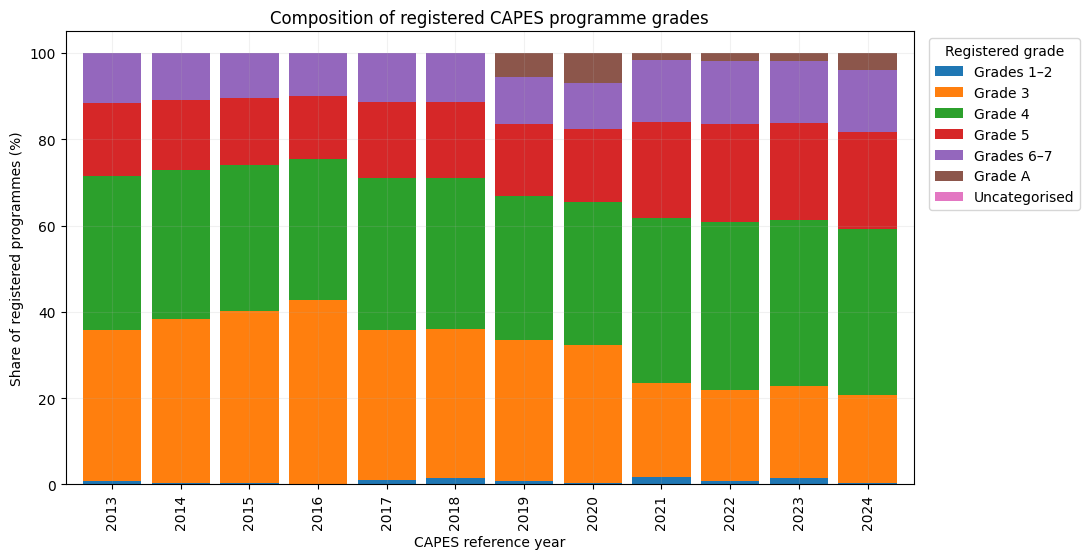

### Figure 4. Registered programmes and programmes with identified theses or dissertations, Brazil, 2013–2024

**Note.** A programme without an identified thesis/dissertation is not necessarily inactive or unproductive; only the frozen CAPES BTD dataset is considered.

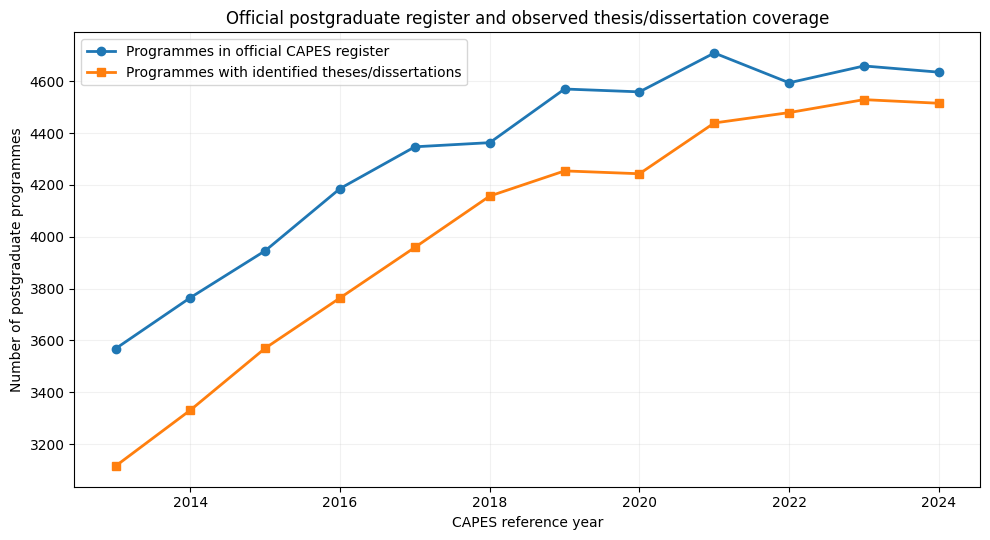

### Figure 5. Concentration of identified theses and dissertations across postgraduate programmes, Brazil, 2013–2024

**Note.** The annual programme universe includes zero observed thesis/dissertation counts. These measures describe identified BTD documents, not all scholarly output.

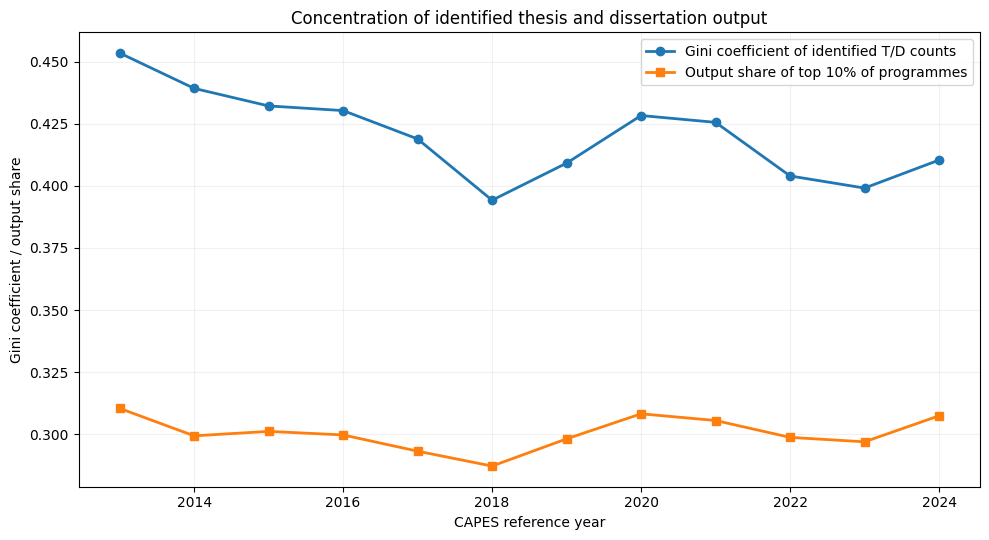


DONE — ALL 10 TABLES PRINTED IN ENGLISH; ALL 5 FIGURES DISPLAYED IN ENGLISH
Saved: 10 English CSV files, 1 English Excel workbook, 5 English PNG figures, 5 PDF figures.
Output folder: /content/drive/MyDrive/CAPES_Epistemic_Change/69_HEQ_ESTRATIFICACAO_INSTITUCIONAL_CENSO_V2_SEPARACAO_CORRIGIDA/04_ENGLISH_ARTICLE_OUTPUTS


In [5]:
# CELL 4/4 — CPU | ACTUAL FIGURES AND TABLES IN ENGLISH, DISPLAYED IN COLAB
# Run AFTER V2 cells 1–3. Does not re-estimate any model.
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
import re

ROOT = Path('/content/drive/MyDrive/CAPES_Epistemic_Change')
SOURCE = ROOT / '69_HEQ_ESTRATIFICACAO_INSTITUCIONAL_CENSO_V2_SEPARACAO_CORRIGIDA'
DEST = SOURCE / '04_ENGLISH_ARTICLE_OUTPUTS'
if not SOURCE.is_dir():
    raise FileNotFoundError(f'Run the V2 laboratory first: {SOURCE}')
DEST.mkdir(parents=True, exist_ok=True)

# Exact source data files used in V2, with no guessed data.
TABLES = [
 ('Table 1','Official postgraduate programme registry and identified theses/dissertations, 2013–2024','01_population_by_year.csv'),
 ('Table 2','Registered CAPES grades by administrative sector, 2013–2024','02_year_administration_stratification.csv'),
 ('Table 3','Registered CAPES grades by programme modality, 2013–2024','02_year_modality_stratification.csv'),
 ('Table 4','Registered CAPES grades by evaluation area, 2013–2024','02_year_area_stratification.csv'),
 ('Table 5','Area-adjusted associations with registered CAPES grades 6–7 among academic programmes','02_glm_adjusted_associations.csv'),
 ('Supplementary Table S1','Changes in programme presence in consecutive annual registers','02_program_registry_entry_exit.csv'),
 ('Supplementary Table S2','Changes in registered CAPES grades between consecutive years','02_concept_registry_transition_by_year.csv'),
 ('Supplementary Table S3','Concentration of identified thesis and dissertation output','02_BTD_concentration_by_year.csv'),
 ('Supplementary Table S4','Coverage of identified theses/dissertations by programme characteristics','02_BTD_coverage_in_official_frame.csv'),
 ('Supplementary Table S5','Model diagnostics for academic-programme area-adjusted regressions','02_glm_fit_diagnostics.csv'),
]
COLS={
 'year':'Year', 'n_ppg_year':'Programmes (n)', 'n_official':'Registered programmes (n)',
 'n_with_BTD':'Programmes with identified T/D (n)','n_docs_BTD':'Identified T/D (n)',
 'n_BTD_docs':'Identified T/D (n)','n_grade_valid':'Programmes with grades 3–7 (n)',
 'n_grade_3to7':'Programmes with grades 3–7 (n)', 'n_high_6_7':'Programmes with grades 6–7 (n)',
 'n_grade_6_7':'Programmes with grades 6–7 (n)',
 'share_high_6_7':'Share with grades 6–7',
 'wilson_low':'Wilson 95% lower limit','wilson_high':'Wilson 95% upper limit',
 'share_with_BTD':'Share with identified T/D',
 'mean_BTD_docs_among_observed':'Mean T/D among observed programmes',
 'administration_norm':'Administrative sector','modality_norm':'Programme modality',
 'area_group':'CAPES evaluation area','grade_band':'Registered grade group',
 'n_ppgs':'Programmes in current register (n)', 'new_vs_previous':'Newly observed vs previous year (n)',
 'exited_vs_previous':'No longer observed vs previous year (n)',
 'retained_from_previous':'Retained from previous year (n)',
 'n_pairs':'Consecutive-year programme pairs (n)',
 'n_grade_changes':'Registered grade changes (n)', 'change_share':'Share with registered grade change',
 'total_BTD_docs':'Identified T/D (n)','gini_BTD_docs_including_zero':'Gini of identified T/D counts',
 'top10pct_ppg_share_BTD_docs':'T/D share of top 10% of programmes',
 'term':'Model term','n':'Observations (n)', 'coefficient':'Log-odds coefficient',
 'robust_SE':'Robust standard error','OR_adjusted_associative':'Adjusted odds ratio',
 'CI95_low':'95% CI lower limit','CI95_high':'95% CI upper limit',
 'p_value_descriptive_model':'Descriptive model p-value',
 'n_areas':'Evaluation areas included (n)', 'support_retained':'Sample retained',
 'modality':'Programme modality','no_events':'No observed events',
 'year_to':'Year of subsequent record',
}
CAT = {'PÚBLICA':'Public','PUBLICA':'Public','PRIVADA':'Private','ACADÊMICO':'Academic',
       'ACADEMICO':'Academic','PROFISSIONAL':'Professional','SEM_CATEGORIA':'Uncategorised',
       'public_vs_private_ACADEMIC_ONLY':'Public vs private (academic only)',
       'public':'Public','professional':'Professional'}
def english_table(df):
    result=df.copy()
    for c in result.select_dtypes(include=['object','string','category']).columns:
        result[c]=result[c].replace(CAT)
    return result.rename(columns={k:v for k,v in COLS.items() if k in result.columns})

def required_csv(name):
    path=SOURCE/name
    if not path.is_file(): raise FileNotFoundError(f'Expected result from V2 not found: {path}')
    return pd.read_csv(path)

# Render ALL ten tables in the Colab output, save English CSVs and one English XLSX.
english_data=[]
with pd.ExcelWriter(DEST/'HEQ_ALL_TABLES_ENGLISH.xlsx',engine='openpyxl') as xls:
    for ix,(label,title,filename) in enumerate(TABLES,1):
        original=required_csv(filename)
        table=english_table(original)
        outname=f'{label.replace(" ","_")}_EN.csv'
        table.to_csv(DEST/outname,index=False,encoding='utf-8-sig')
        table.to_excel(xls,sheet_name=f'{"T" if ix<=5 else "S"}{ix if ix<=5 else ix-5}',index=False)
        english_data.append({'label':label,'title':title,'source':filename,'english_file':outname,
                             'rows':len(table)})
        display(Markdown(f'### {label}. {title}'))
        if ix==5:
            display(Markdown('**Note.** Academic programmes only; public vs private, adjusted for CAPES evaluation area in areas with common support. Grade 6–7 versus grade 3–5. Robust HC1 standard errors; associational, not causal.'))
        display(table)
        print(f'English table saved: {DEST/outname} | {len(table):,} rows')

# Rebuild ALL five figures using exact CSV values from V2. Plot text and displayed notes are English.
FIGS=[]
def finish(fig,ax,filename,caption,note):
    ax.grid(alpha=.17)
    fig.tight_layout()
    fig.savefig(DEST/filename,dpi=240,bbox_inches='tight')
    fig.savefig(DEST/filename.replace('.png','.pdf'),bbox_inches='tight')
    display(Markdown(f'### {caption}'))
    display(Markdown(f'**Note.** {note}'))
    plt.show()
    plt.close(fig)
    FIGS.append({'figure':caption,'png':filename,'pdf':filename.replace('.png','.pdf'),'note':note})

# Figure 1: registered grades 6–7 by administrative sector
ad=required_csv('02_year_administration_stratification.csv')
fig,ax=plt.subplots(figsize=(10,5.5))
for key,group in ad.groupby('administration_norm',dropna=False):
    ax.plot(group.year,group.share_high_6_7,marker='o',linewidth=2,label=CAT.get(str(key),str(key)))
ax.set(title='Registered CAPES grades 6–7 by administrative sector',xlabel='CAPES reference year',
       ylabel='Share among programmes with grades 3–7')
ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend(title='Administrative sector')
finish(fig,ax,'Figure_1_EN.png','Figure 1. Share of programmes with registered CAPES grades 6–7 by administrative sector, Brazil, 2013–2024',
       'The denominator includes programmes with grades 3–7 in each administrative sector and year; recorded grades do not identify annual evaluation events.')

# Figure 2: registered grades 6–7 by modality
md=required_csv('02_year_modality_stratification.csv')
fig,ax=plt.subplots(figsize=(10,5.5))
for key,group in md.groupby('modality_norm',dropna=False):
    ax.plot(group.year,group.share_high_6_7,marker='o',linewidth=2,label=CAT.get(str(key),str(key)))
ax.set(title='Registered CAPES grades 6–7 by programme modality',xlabel='CAPES reference year',
       ylabel='Share among programmes with grades 3–7')
ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend(title='Programme modality')
finish(fig,ax,'Figure_2_EN.png','Figure 2. Share of programmes with registered CAPES grades 6–7 by academic or professional modality, Brazil, 2013–2024',
       'No grade 6–7 was observed for professional programmes in the analysed registry; this is a descriptive zero, not an estimated odds ratio or proof of equivalent evaluation rules.')

# Figure 3: full denominator including unclassified and A
bands=required_csv('02_year_grade_stratification.csv')
if 'n_ppg_year' not in bands: raise ValueError('Missing n_ppg_year in grade-stratification source')
order=['1-2','3','4','5','6-7','A','SEM_CATEGORIA']
full=bands.pivot_table(index='year',columns='grade_band',values='n_ppg_year',aggfunc='sum',fill_value=0)
full=full.reindex(columns=order,fill_value=0)
shares=full.div(full.sum(axis=1),axis=0)*100
shares.columns=['Grades 1–2','Grade 3','Grade 4','Grade 5','Grades 6–7','Grade A','Uncategorised']
fig,ax=plt.subplots(figsize=(11,5.7))
shares.plot(kind='bar',stacked=True,ax=ax,width=.85)
ax.set(title='Composition of registered CAPES programme grades',xlabel='CAPES reference year',ylabel='Share of registered programmes (%)')
ax.legend(title='Registered grade',bbox_to_anchor=(1.01,1),loc='upper left')
finish(fig,ax,'Figure_3_EN.png','Figure 3. Distribution of registered CAPES programme grades in Brazil, 2013–2024',
       'The denominator includes all programmes in the official register for each year. Grade A and uncategorised records are displayed separately.')

# Figure 4: official versus identified BTD
pop=required_csv('01_population_by_year.csv')
fig,ax=plt.subplots(figsize=(10,5.5))
ax.plot(pop.year,pop.n_official,marker='o',linewidth=2,label='Programmes in official CAPES register')
ax.plot(pop.year,pop.n_with_BTD,marker='s',linewidth=2,label='Programmes with identified theses/dissertations')
ax.set(title='Official postgraduate register and observed thesis/dissertation coverage',
       xlabel='CAPES reference year',ylabel='Number of postgraduate programmes')
ax.legend()
finish(fig,ax,'Figure_4_EN.png','Figure 4. Registered programmes and programmes with identified theses or dissertations, Brazil, 2013–2024',
       'A programme without an identified thesis/dissertation is not necessarily inactive or unproductive; only the frozen CAPES BTD dataset is considered.')

# Figure 5: Gini and top 10% concentration
conc=required_csv('02_BTD_concentration_by_year.csv')
fig,ax=plt.subplots(figsize=(10,5.5))
ax.plot(conc.year,conc.gini_BTD_docs_including_zero,marker='o',linewidth=2,label='Gini coefficient of identified T/D counts')
ax.plot(conc.year,conc.top10pct_ppg_share_BTD_docs,marker='s',linewidth=2,label='Output share of top 10% of programmes')
ax.set(title='Concentration of identified thesis and dissertation output',xlabel='CAPES reference year',
       ylabel='Gini coefficient / output share')
ax.legend()
finish(fig,ax,'Figure_5_EN.png','Figure 5. Concentration of identified theses and dissertations across postgraduate programmes, Brazil, 2013–2024',
       'The annual programme universe includes zero observed thesis/dissertation counts. These measures describe identified BTD documents, not all scholarly output.')

# Print complete manifest in Colab and save it with the actual English items.
manifest=pd.concat([
    pd.DataFrame(english_data).assign(item_type='Table'),
    pd.DataFrame(FIGS).assign(item_type='Figure')
],ignore_index=True)
manifest.to_csv(DEST/'HEQ_ENGLISH_OUTPUT_MANIFEST.csv',index=False,encoding='utf-8-sig')
print('\n'+'='*78)
print('DONE — ALL 10 TABLES PRINTED IN ENGLISH; ALL 5 FIGURES DISPLAYED IN ENGLISH')
print('Saved: 10 English CSV files, 1 English Excel workbook, 5 English PNG figures, 5 PDF figures.')
print('Output folder:',DEST)
print('='*78)
